# Model comparison: where the lesion is, and whether it is benign or malignant

Ten models: five families (CNN, Faster R-CNN, YOLO, grid stacker, set stacker), each under both
held-out protocols, the five-fold ensemble of the fold checkpoints and the single model
retrained on all of trainval.

The two questions and the metric that answers each:

- **Where is the lesion** - FROC: sensitivity against false positives per mammogram, with AP50
  beside it as the threshold-free summary the detector tables already report.
- **Benign or malignant** - sensitivity and precision per class over the matched ground truth,
  and the confusion matrix behind them. FROC and class-agnostic AP50 ignore the class label,
  so neither can answer this half.

Every number comes from the held-out test split through `final_eval`, which trains nothing. The
ensemble protocol pools each fold's prediction of the same mammogram, so no test mammogram was
seen by the model that predicts it. The full-trainval models saw all of trainval, and the test
split is the only honest score they have.

No model ships an operating threshold. Every checkpoint is exported at a low collection floor,
which is what keeps the stacker's candidate recall ceiling high; the score at which a detection
is finally called is a choice made here, not a property of the weights.

---

## Where the operating threshold comes from

A FROC curve is a family of operating points, not a model score: every point is one score
threshold, and moving down the curve trades false positives per mammogram for sensitivity. The
threshold is therefore chosen by choosing the point, and the point is a false-positive budget,
not a property of the model. This notebook reads the threshold at `FROC_FP_BUDGET` false
positives per mammogram below, and that is the only operating point in the whole comparison:
P, R, F1, detections and false positives per mammogram are all reported there. Sensitivities at
the usual literature points are printed too, so a different budget can be read off the same
curves without rerunning anything.

In [2]:
# Block 1
%load_ext autoreload
%autoreload 1

# Watch the modules these cells call into
%aimport utility
%aimport config
%aimport Detector
%aimport cnn_detector
%aimport faster_rcnn_detector
%aimport yolo_detector
%aimport stacker
%aimport stacker_set
%aimport final_eval
%aimport final_retrain

import os

# Keras reads the backend before it is imported
os.environ["KERAS_BACKEND"] = "torch"

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

import config
import utility

import cnn_detector
import Detector
import final_eval

In [3]:
# Block 2
LESION_TYPE = "mass"

# The 10 models: five families, each under both protocols
FAMILIES = ("cnn", "faster_rcnn", "yolo", final_eval.GRID_NAME, final_eval.SET_NAME)
FAMILY_LABELS = {
    "cnn": "CNN",
    "faster_rcnn": "Faster R-CNN",
    "yolo": "YOLO",
    final_eval.GRID_NAME: "Stacker (grid)",
    final_eval.SET_NAME: "Stacker (set)",
}

# One detector per family under the full protocol, and both stackers on their candidates
FULL_KEY = {
    "cnn": "cnn",
    "faster_rcnn": "faster_rcnn",
    "yolo": "yolo",
    final_eval.GRID_NAME: final_eval.FULL_GRID_NAME,
    final_eval.SET_NAME: final_eval.FULL_NAME,
}
FULL_RETRAIN_KEY = {
    "cnn": "cnn",
    "faster_rcnn": "faster_rcnn",
    "yolo": "yolo",
    final_eval.GRID_NAME: "stacker_grid",
    final_eval.SET_NAME: "stacker_set",
}

ENSEMBLE = "5-fold ensemble"
FULL = "full trainval"
PROTOCOLS = (ENSEMBLE, FULL)

MODELS = [
    (FAMILY_LABELS[family], protocol, key)
    for family in FAMILIES
    for protocol, key in ((ENSEMBLE, family), (FULL, FULL_KEY[family]))
]


def by_protocol(protocol):
    """The five families of one protocol, in family order."""
    return [(label, name, key) for label, name, key in MODELS if name == protocol]


# FROC: sensitivity against false positives per mammogram, read at the usual literature points
FROC_FP_POINTS = (0.125, 0.25, 0.5, 1.0, 2.0, 4.0, 8.0)
FROC_FP_BUDGET = 1.0
FROC_X_MAX = 8.0
IOU_THRESHOLD = config.CNN_IOU_THRESHOLD

print(f"Models : {len(MODELS)}, {len(FAMILIES)} families x {len(PROTOCOLS)} protocols")
print(f"FROC   : match at IoU {IOU_THRESHOLD}, budget {FROC_FP_BUDGET:g} false positives per mammogram")
print(f"Points : {', '.join(f'{point:g}' for point in FROC_FP_POINTS)}")

Models : 10, 5 families x 2 protocols
FROC   : match at IoU 0.5, budget 1 false positives per mammogram
Points : 0.125, 0.25, 0.5, 1, 2, 4, 8


In [4]:
# Block 3
def froc_curve(raw, iou_threshold=IOU_THRESHOLD):
    """Sensitivity against false positives per mammogram, over one model's own score sweep."""
    scores = []
    hits = []
    total_gt = 0

    for entry in raw:
        boxes = np.asarray(entry["boxes"], np.float32).reshape(-1, 4)
        gt_boxes = np.asarray(entry["gt_boxes"], np.float32).reshape(-1, 4)
        values = np.asarray(entry["scores"], np.float32).reshape(-1)

        total_gt += len(gt_boxes)
        matched = utility.match_detections_to_gt(boxes, values, gt_boxes, iou_threshold)

        scores.append(values)
        hits.append(matched >= 0)

    scores = np.concatenate(scores).astype(np.float32)
    hits = np.concatenate(hits)

    order = np.argsort(-scores)
    scores = scores[order]
    hits = hits[order]

    true_positive = np.cumsum(hits)
    false_positive = np.cumsum(~hits)

    # A leading (0, 0) point, so a threshold above every detection is representable
    thresholds = np.concatenate(([np.inf], scores))
    sensitivity = np.concatenate(([0.0], true_positive / max(total_gt, 1)))
    fp_per_image = np.concatenate(([0.0], false_positive / max(len(raw), 1)))

    return thresholds, sensitivity, fp_per_image


def froc_sensitivity(sensitivity, fp_per_image, fp_point):
    """Sensitivity at the last point inside a false-positive budget."""
    inside = fp_per_image <= fp_point

    return float(sensitivity[inside].max()) if inside.any() else 0.0


def froc_threshold(thresholds, sensitivity, fp_per_image, fp_budget):
    """Score threshold of the highest-sensitivity point inside the budget; NaN if never inside."""
    inside = (fp_per_image <= fp_budget) & np.isfinite(thresholds)

    if not inside.any():
        return np.nan

    candidates = np.flatnonzero(inside)

    return float(thresholds[candidates[np.argmax(sensitivity[candidates])]])


def ap_metrics(raw, iou_threshold=IOU_THRESHOLD):
    """AP50 and macro per-class AP50 over every detection, with no operating point."""
    predictions = [{"boxes": entry["boxes"], "scores": entry["scores"], "labels": entry["labels"]} for entry in raw]
    targets = [{"boxes": entry["gt_boxes"], "labels": entry["gt_labels"]} for entry in raw]

    return utility.evaluate_detector_by_class(predictions, targets, iou_threshold=iou_threshold)


def cut_at(raw, threshold):
    """Each mammogram's detections at or above a score threshold."""
    cut = []

    for entry in raw:
        scores = np.asarray(entry["scores"], np.float32).reshape(-1)
        keep = scores >= threshold

        cut.append(
            {
                **entry,
                "boxes": np.asarray(entry["boxes"], np.float32).reshape(-1, 4)[keep],
                "scores": scores[keep],
                "labels": np.asarray(entry["labels"], np.int64).reshape(-1)[keep],
                "class_scores": np.asarray(entry["class_scores"], np.float32).reshape(-1)[keep],
            }
        )

    return cut


def confusion_report(matrix):
    """Per-class sensitivity and precision, plus class accuracy over the localised boxes."""
    names = list(config.CLASS_NAMES)
    localised = matrix.loc[names, names].to_numpy()
    matched = localised.sum()

    report = {}

    for name in names:
        positives = matrix.loc[name].sum()
        predicted = matrix[name].sum()

        report[f"{name} sens"] = matrix.loc[name, name] / positives if positives else np.nan
        report[f"{name} prec"] = matrix.loc[name, name] / predicted if predicted else np.nan

    report["class acc"] = np.trace(localised) / matched if matched else np.nan

    return report

In [5]:
# Block 4
test_df, ids, ground_truth, folds = final_eval.load_test()


def size_mb(path):
    """Checkpoint size in MB, or NaN while the file is not there yet."""
    return round(path.stat().st_size / 1e6, 1) if path.exists() else np.nan


# Every checkpoint this comparison reads, so a missing one is visible before inference starts
checkpoints = []

for family in FAMILIES:
    for fold in folds:
        path = config.fold_paths(family, LESION_TYPE, fold)["model"]
        checkpoints.append((FAMILY_LABELS[family], ENSEMBLE, path, path.exists(), size_mb(path)))

    path = final_retrain.OUTPUTS[FULL_RETRAIN_KEY[family]]
    checkpoints.append((FAMILY_LABELS[family], FULL, path, path.exists(), size_mb(path)))

present = pd.DataFrame(checkpoints, columns=["model", "protocol", "path", "present", "MB"])

display(
    present.groupby(["model", "protocol"], as_index=False).agg(
        checkpoints=("present", "size"), present=("present", "sum"), MB=("MB", "sum")
    )
)

if not present["present"].all():
    missing = present.loc[~present["present"], "path"].tolist()
    raise FileNotFoundError("Train these before comparing:\n" + "\n".join(str(path) for path in missing))

Test mammograms: 320, 341 lesions, folds [0, 1, 2, 3, 4]


,model,protocol,checkpoints,present,MB
0,CNN,5-fold ensemble,5,5,48.5
1,CNN,full trainval,1,1,9.7
2,Faster R-CNN,5-fold ensemble,5,5,380.5
3,Faster R-CNN,full trainval,1,1,76.1
4,Stacker (grid),5-fold ensemble,5,5,126.0
5,Stacker (grid),full trainval,1,1,25.2
6,Stacker (set),5-fold ensemble,5,5,17.0
7,Stacker (set),full trainval,1,1,3.4
8,YOLO,5-fold ensemble,5,5,101.5
9,YOLO,full trainval,1,1,20.3


In [6]:
# Block 5
# Every model predicts the held-out test split; the ensemble pools each fold's predictions
progress = tqdm(total=0, desc="Test inference", position=0)

try:
    ensemble_raw, _ = final_eval.raw_folds(test_df, ids, ground_truth, folds, progress=progress)
    full_raw = final_eval.raw_full(test_df, ids, ground_truth, folds, progress=progress)
finally:
    progress.close()

RAW = {(FAMILY_LABELS[family], ENSEMBLE): ensemble_raw[family] for family in FAMILIES} | {
    (FAMILY_LABELS[family], FULL): full_raw[FULL_KEY[family]] for family in FAMILIES
}

# Each model's own detections above its export floor, so the counts differ by model
counts = pd.DataFrame(
    [
        {
            "model": label,
            "protocol": protocol,
            "detections": sum(len(entry["scores"]) for entry in RAW[(label, protocol)]),
            "mammograms": len(RAW[(label, protocol)]),
        }
        for label, protocol, _ in MODELS
    ]
)
counts["per mammogram"] = counts["detections"] / counts["mammograms"]

display(counts.round(2))

Test inference: 0it [00:00, ?it/s]

=== fold 0 ===


 fold     detector records candidates
    0          CNN   4,466     15,567
    0 Faster R-CNN   1,427     13,447
    0         YOLO     823      9,794
=== fold 1 ===
 fold     detector records candidates
    1          CNN   4,041     15,847
    1 Faster R-CNN   1,065     13,296
    1         YOLO     890     10,969
=== fold 2 ===
 fold     detector records candidates
    2          CNN   4,725     15,737
    2 Faster R-CNN   1,120     13,376
    2         YOLO     817     10,988
=== fold 3 ===
 fold     detector records candidates
    3          CNN   4,178     15,617
    3 Faster R-CNN   1,555     14,822
    3         YOLO     681      6,998
=== fold 4 ===
 fold     detector records candidates
    4          CNN   5,084     15,814
    4 Faster R-CNN     969     11,441
    4         YOLO     768      8,558
    detector records candidates
         CNN   4,883     15,896
Faster R-CNN     830     11,024
        YOLO     666      8,463


,model,protocol,detections,mammograms,per mammogram
0,CNN,5-fold ensemble,7094,320,22.17
1,CNN,full trainval,4883,320,15.26
2,Faster R-CNN,5-fold ensemble,884,320,2.76
3,Faster R-CNN,full trainval,830,320,2.59
4,YOLO,5-fold ensemble,1021,320,3.19
5,YOLO,full trainval,666,320,2.08
6,Stacker (grid),5-fold ensemble,7586,320,23.71
7,Stacker (grid),full trainval,3949,320,12.34
8,Stacker (set),5-fold ensemble,2794,320,8.73
9,Stacker (set),full trainval,1591,320,4.97


AP50   mAP50     CPM  sens @ 0.125  \
model          protocol                                                
CNN            5-fold ensemble  0.4933  0.2096  0.5832        0.3372   
               full trainval    0.4939  0.2209  0.5815        0.3724   
Faster R-CNN   5-fold ensemble  0.4963  0.3626  0.5756        0.3930   
               full trainval    0.4681  0.3959  0.5626        0.3695   
YOLO           5-fold ensemble  0.6195  0.4329  0.6862        0.4575   
               full trainval    0.5573  0.4376  0.6339        0.3988   
Stacker (grid) 5-fold ensemble  0.5745  0.3777  0.6213        0.3988   
               full trainval    0.5322  0.3199  0.6075        0.3724   
Stacker (set)  5-fold ensemble  0.5639  0.3448  0.6456        0.3871   
               full trainval    0.5529  0.3916  0.6410        0.4311   

                                sens @ 0.25  sens @ 0.5  sens @ 1  sens @ 2  \
model          protocol                                                       
CNN            5-fold ensemble       0.4487      0.5484    0.6012    0.6745   
               full trainval         0.4311      0.5396    0.6100    0.6628   
Faster R-CNN   5-fold ensemble       0.4780      0.5543    0.6158    0.6628   
               full trainval         0.4780      0.5161    0.5953    0.6598   
YOLO           5-fold ensemble       0.5660      0.6422    0.7331    0.7977   
               full trainval         0.5191      0.6276    0.7097    0.7273   
Stacker (grid) 5-fold ensemble       0.4927      0.5865    0.6745    0.7155   
               full trainval         0.4927      0.5953    0.6745    0.6950   
Stacker (set)  5-fold ensemble       0.5015      0.6012    0.6950    0.7595   
               full trainval         0.5015      0.6158    0.6862    0.7331   

                                sens @ 4  sens @ 8  FP/img max  FROC thr  \
model          protocol                                                    
CNN            5-fold ensemble    0.7302    0.7419     21.3594    0.9535   
               full trainval      0.7126    0.7419     14.4656    0.9079   
Faster R-CNN   5-fold ensemble    0.6628    0.6628      2.0562    0.1905   
               full trainval      0.6598    0.6598      1.8906    0.1231   
YOLO           5-fold ensemble    0.8035    0.8035      2.3344    0.1504   
               full trainval      0.7273    0.7273      1.3062    0.0657   
Stacker (grid) 5-fold ensemble    0.7361    0.7449     22.8906    1.0000   
               full trainval      0.7038    0.7185     11.5688    0.9503   
Stacker (set)  5-fold ensemble    0.7771    0.7977      7.8812    0.5892   
               full trainval      0.7595    0.7595      4.1625    0.3516   

                                FP/img @ budget  
model          protocol                          
CNN            5-fold ensemble              1.0  
               full trainval                1.0  
Faster R-CNN   5-fold ensemble              1.0  
               full trainval                1.0  
YOLO           5-fold ensemble              1.0  
               full trainval                1.0  
Stacker (grid) 5-fold ensemble              1.0  
               full trainval                1.0  
Stacker (set)  5-fold ensemble              1.0  
               full trainval                1.0

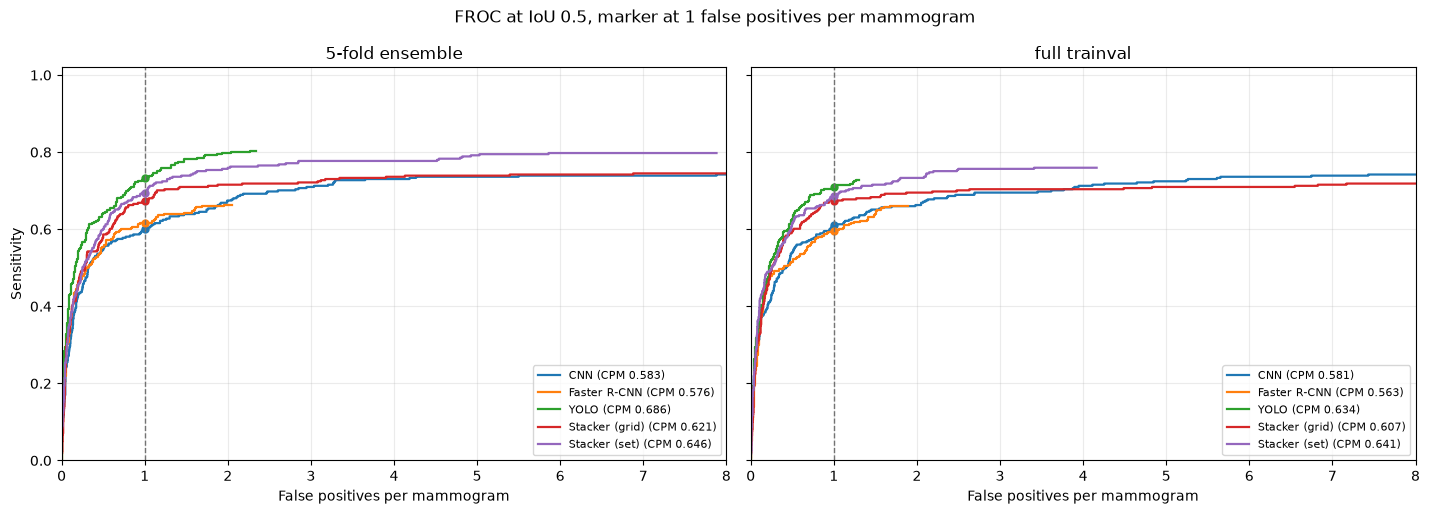

In [7]:
# Block 6
# Q1: the FROC curve and AP50 for each model, with the operating point read at the budget
FROC = {(label, protocol): froc_curve(RAW[(label, protocol)], IOU_THRESHOLD) for label, protocol, _ in MODELS}
OPERATING = {}

rows = []

for label, protocol, _ in MODELS:
    thresholds, sensitivity, fp_per_image = FROC[(label, protocol)]
    metrics = ap_metrics(RAW[(label, protocol)], IOU_THRESHOLD)
    operating = froc_threshold(thresholds, sensitivity, fp_per_image, FROC_FP_BUDGET)

    OPERATING[(label, protocol)] = operating

    rows.append(
        {
            "model": label,
            "protocol": protocol,
            "AP50": metrics["ap50"],
            "mAP50": metrics["ap50_macro"],
            "CPM": float(np.mean([froc_sensitivity(sensitivity, fp_per_image, point) for point in FROC_FP_POINTS])),
            **{f"sens @ {point:g}": froc_sensitivity(sensitivity, fp_per_image, point) for point in FROC_FP_POINTS},
            "FP/img max": float(fp_per_image[-1]),
            "FROC thr": operating,
            "FP/img @ budget": float(fp_per_image[fp_per_image <= FROC_FP_BUDGET].max()),
        }
    )

froc_summary = pd.DataFrame(rows).set_index(["model", "protocol"])

display(froc_summary.round(4))

figure, axes = plt.subplots(1, len(PROTOCOLS), figsize=(7.2 * len(PROTOCOLS), 5.2), sharey=True)

for axis, protocol in zip(np.atleast_1d(axes), PROTOCOLS):
    for label, _, _ in by_protocol(protocol):
        _, sensitivity, fp_per_image = FROC[(label, protocol)]

        (line,) = axis.plot(
            fp_per_image,
            sensitivity,
            lw=1.6,
            label=f"{label} (CPM {froc_summary.loc[(label, protocol), 'CPM']:.3f})",
        )
        axis.plot(
            [FROC_FP_BUDGET],
            [froc_sensitivity(sensitivity, fp_per_image, FROC_FP_BUDGET)],
            marker="o",
            ms=5,
            color=line.get_color(),
        )

    axis.axvline(FROC_FP_BUDGET, color="0.45", ls="--", lw=1)
    axis.set_xlim(0, FROC_X_MAX)
    axis.set_ylim(0, 1.02)
    axis.set_xlabel("False positives per mammogram")
    axis.set_title(protocol)
    axis.grid(alpha=0.25)
    axis.legend(fontsize=8, loc="lower right")

axes[0].set_ylabel("Sensitivity")
figure.suptitle(f"FROC at IoU {IOU_THRESHOLD}, marker at {FROC_FP_BUDGET:g} false positives per mammogram")
plt.tight_layout()
plt.show()

In [8]:
# Block 7
# Threshold-dependent metrics of the ten models at the FROC operating point
rows = []

for label, protocol, _ in MODELS:
    raw = RAW[(label, protocol)]
    threshold = OPERATING[(label, protocol)]
    metrics = Detector.detection_metrics(raw, IOU_THRESHOLD, threshold)
    matrix = utility.detection_confusion(cut_at(raw, threshold), iou_threshold=IOU_THRESHOLD)

    rows.append(
        {
            "model": label,
            "protocol": protocol,
            "threshold": threshold,
            "P": metrics["precision"],
            "R": metrics["recall"],
            "F1": metrics["f1"],
            "Det/img": metrics["det_per_image"],
            "FP/img": matrix.loc["background"].sum() / len(ids),
            **confusion_report(matrix),
        }
    )

froc_table = pd.DataFrame(rows).set_index(["model", "protocol"])

print(f"Every model at the FROC operating threshold, {FROC_FP_BUDGET:g} false positives per mammogram")
display(froc_table.round(4))

Every model at the FROC operating threshold, 1 false positives per mammogram


threshold       P       R      F1  Det/img  \
model          protocol                                                      
CNN            5-fold ensemble     0.9535  0.3935  0.6012  0.4756   1.6281   
               full trainval       0.9079  0.3992  0.6100  0.4826   1.6281   
Faster R-CNN   5-fold ensemble     0.1905  0.4118  0.6158  0.4935   1.5938   
               full trainval       0.1231  0.3881  0.5953  0.4699   1.6344   
YOLO           5-fold ensemble     0.1504  0.4394  0.7331  0.5495   1.7781   
               full trainval       0.0657  0.4329  0.7097  0.5378   1.7469   
Stacker (grid) 5-fold ensemble     1.0000  0.4182  0.6745  0.5163   1.7188   
               full trainval       0.9503  0.4331  0.6745  0.5275   1.6594   
Stacker (set)  5-fold ensemble     0.5892  0.4333  0.6950  0.5338   1.7094   
               full trainval       0.3516  0.4239  0.6862  0.5241   1.7250   

                                FP/img  benign sens  benign prec  \
model          protocol                                            
CNN            5-fold ensemble  0.9875       0.3636       0.2244   
               full trainval    0.9781       0.4225       0.2394   
Faster R-CNN   5-fold ensemble  0.9375       0.4866       0.3216   
               full trainval    1.0000       0.4866       0.3106   
YOLO           5-fold ensemble  0.9969       0.5561       0.3095   
               full trainval    0.9906       0.5722       0.3429   
Stacker (grid) 5-fold ensemble  1.0000       0.4332       0.3164   
               full trainval    0.9406       0.4492       0.2917   
Stacker (set)  5-fold ensemble  0.9688       0.4492       0.3294   
               full trainval    0.9938       0.5561       0.3210   

                                malignant sens  malignant prec  class acc  
model          protocol                                                    
CNN            5-fold ensemble          0.3831          0.2706     0.6195  
               full trainval            0.3766          0.3037     0.6587  
Faster R-CNN   5-fold ensemble          0.5000          0.3392     0.8000  
               full trainval            0.4935          0.3304     0.8227  
YOLO           5-fold ensemble          0.5909          0.3906     0.7800  
               full trainval            0.5714          0.3563     0.8058  
Stacker (grid) 5-fold ensemble          0.5714          0.2993     0.7348  
               full trainval            0.4740          0.3004     0.6826  
Stacker (set)  5-fold ensemble          0.5909          0.3116     0.7384  
               full trainval            0.5325          0.3596     0.7949

In [9]:
# Block 8
# Q2: per-class sensitivity and precision, plus class accuracy over the localised boxes
CLASS_COLUMNS = ["benign sens", "benign prec", "malignant sens", "malignant prec", "class acc"]

print(f"Class metrics at the FROC operating threshold, {FROC_FP_BUDGET:g} false positives per mammogram")
display(froc_table[CLASS_COLUMNS].round(4))

Class metrics at the FROC operating threshold, 1 false positives per mammogram


benign sens  benign prec  malignant sens  \
model          protocol                                                    
CNN            5-fold ensemble       0.3636       0.2244          0.3831   
               full trainval         0.4225       0.2394          0.3766   
Faster R-CNN   5-fold ensemble       0.4866       0.3216          0.5000   
               full trainval         0.4866       0.3106          0.4935   
YOLO           5-fold ensemble       0.5561       0.3095          0.5909   
               full trainval         0.5722       0.3429          0.5714   
Stacker (grid) 5-fold ensemble       0.4332       0.3164          0.5714   
               full trainval         0.4492       0.2917          0.4740   
Stacker (set)  5-fold ensemble       0.4492       0.3294          0.5909   
               full trainval         0.5561       0.3210          0.5325   

                                malignant prec  class acc  
model          protocol                                    
CNN            5-fold ensemble          0.2706     0.6195  
               full trainval            0.3037     0.6587  
Faster R-CNN   5-fold ensemble          0.3392     0.8000  
               full trainval            0.3304     0.8227  
YOLO           5-fold ensemble          0.3906     0.7800  
               full trainval            0.3563     0.8058  
Stacker (grid) 5-fold ensemble          0.2993     0.7348  
               full trainval            0.3004     0.6826  
Stacker (set)  5-fold ensemble          0.3116     0.7384  
               full trainval            0.3596     0.7949

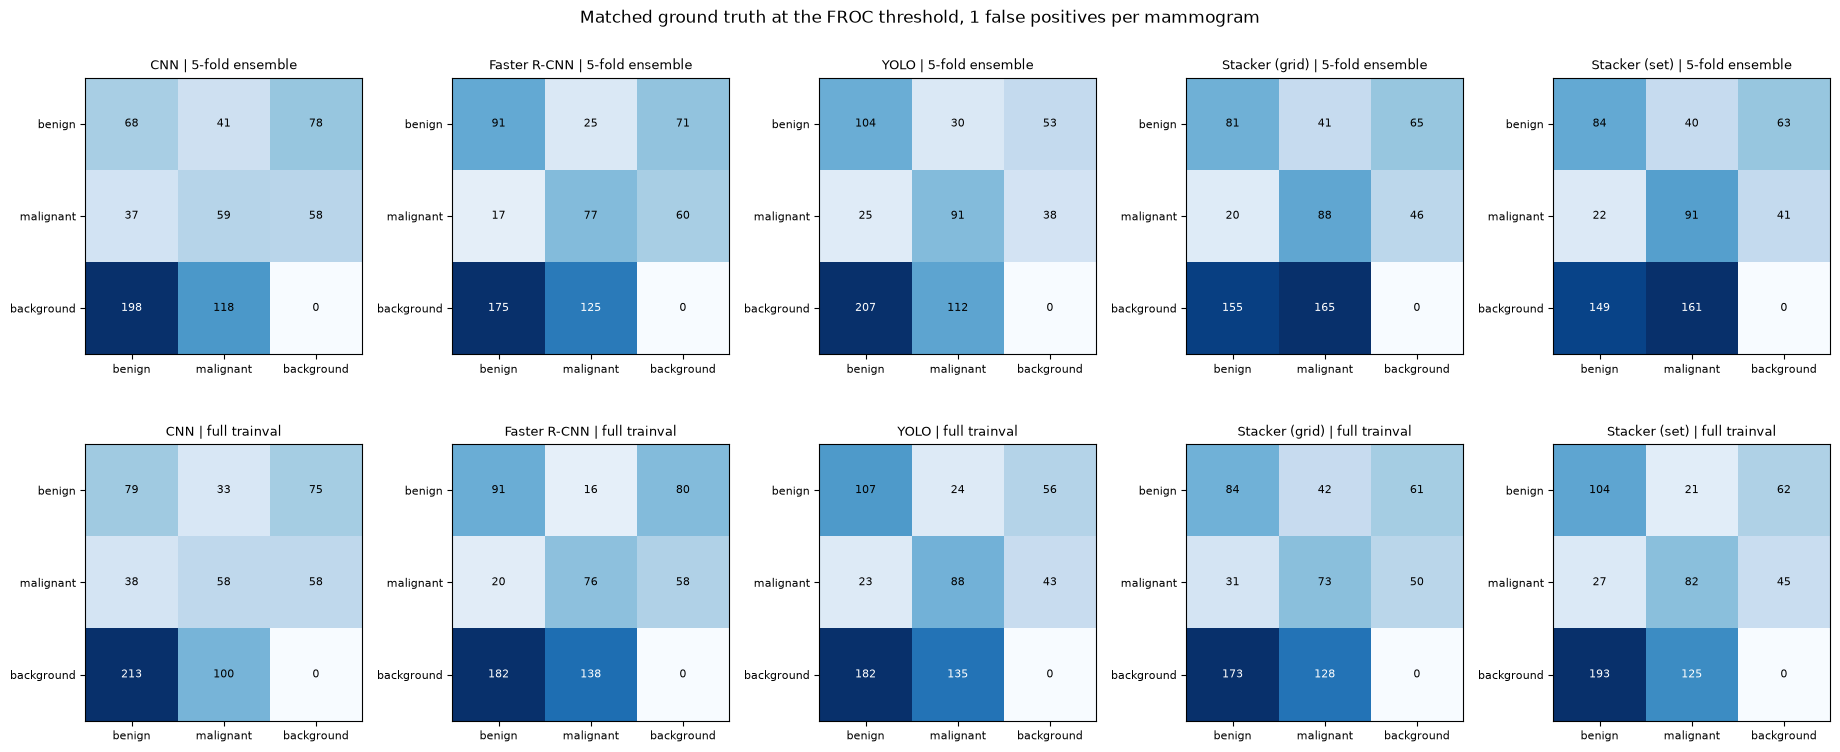

In [10]:
# Block 9
# Confusion matrices behind the class numbers: rows are ground truth, columns predictions
def plot_confusions(at, title):
    """One matched-ground-truth confusion per model, five families per protocol row."""
    order = [entry for protocol in PROTOCOLS for entry in by_protocol(protocol)]

    figure, axes = plt.subplots(2, len(FAMILIES), figsize=(3.7 * len(FAMILIES), 7.8))

    for axis, (label, protocol, _) in zip(axes.ravel(), order):
        matrix = utility.detection_confusion(cut_at(RAW[(label, protocol)], at[(label, protocol)]), IOU_THRESHOLD)
        values = matrix.to_numpy()
        limit = max(values.max(), 1)

        axis.imshow(values, cmap="Blues", vmin=0, vmax=limit)
        axis.set_xticks(range(len(matrix.columns)), labels=matrix.columns, fontsize=8)
        axis.set_yticks(range(len(matrix.index)), labels=matrix.index, fontsize=8)
        axis.set_title(f"{label} | {protocol}", fontsize=9)

        for row in range(values.shape[0]):
            for column in range(values.shape[1]):
                axis.text(
                    column,
                    row,
                    f"{values[row, column]:,}",
                    ha="center",
                    va="center",
                    fontsize=8,
                    color="white" if values[row, column] > 0.6 * limit else "black",
                )

    figure.suptitle(title)
    plt.tight_layout()
    plt.show()


plot_confusions(
    OPERATING, f"Matched ground truth at the FROC threshold, {FROC_FP_BUDGET:g} false positives per mammogram"
)

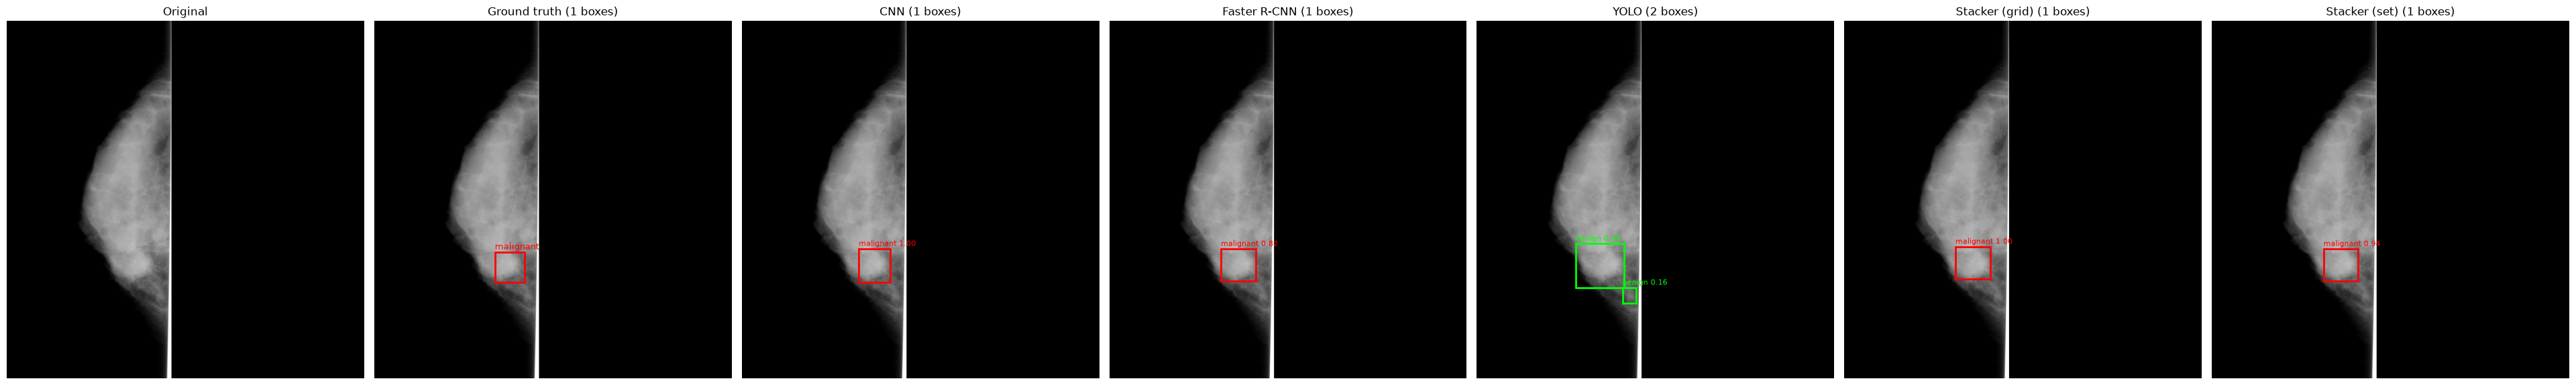

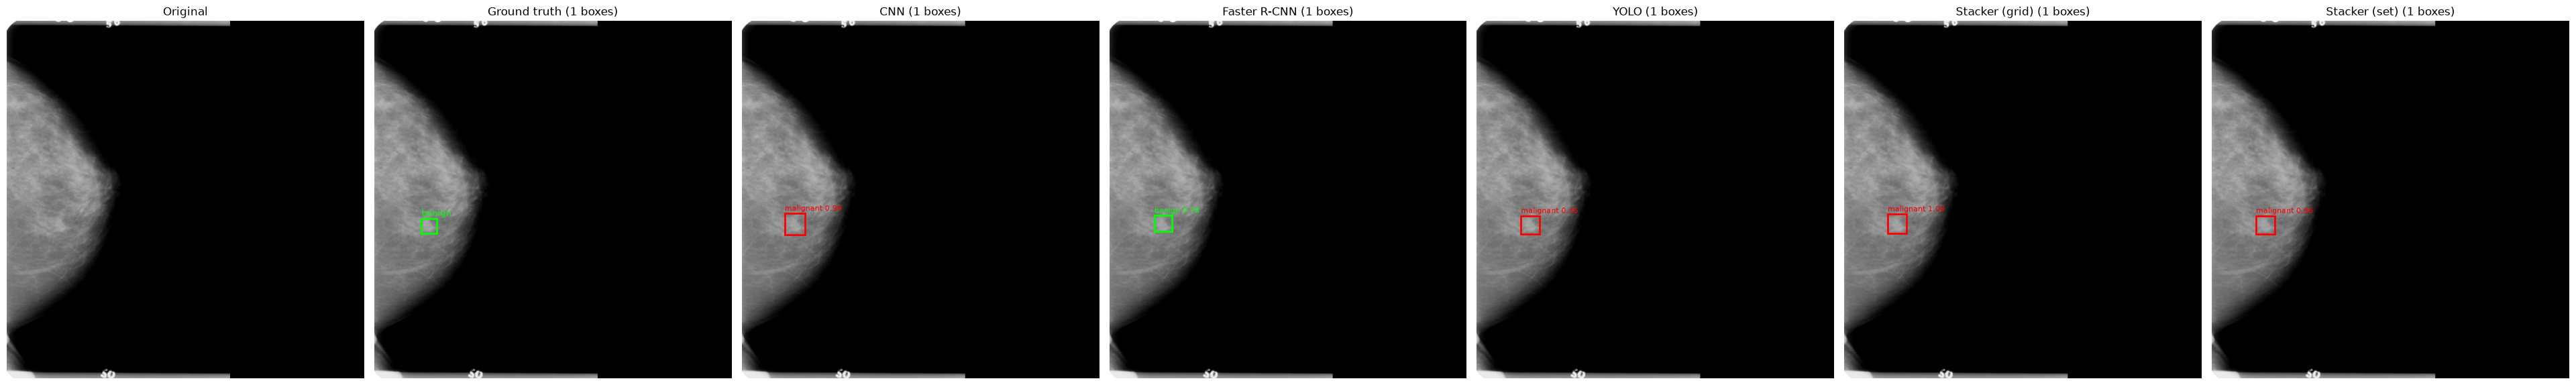

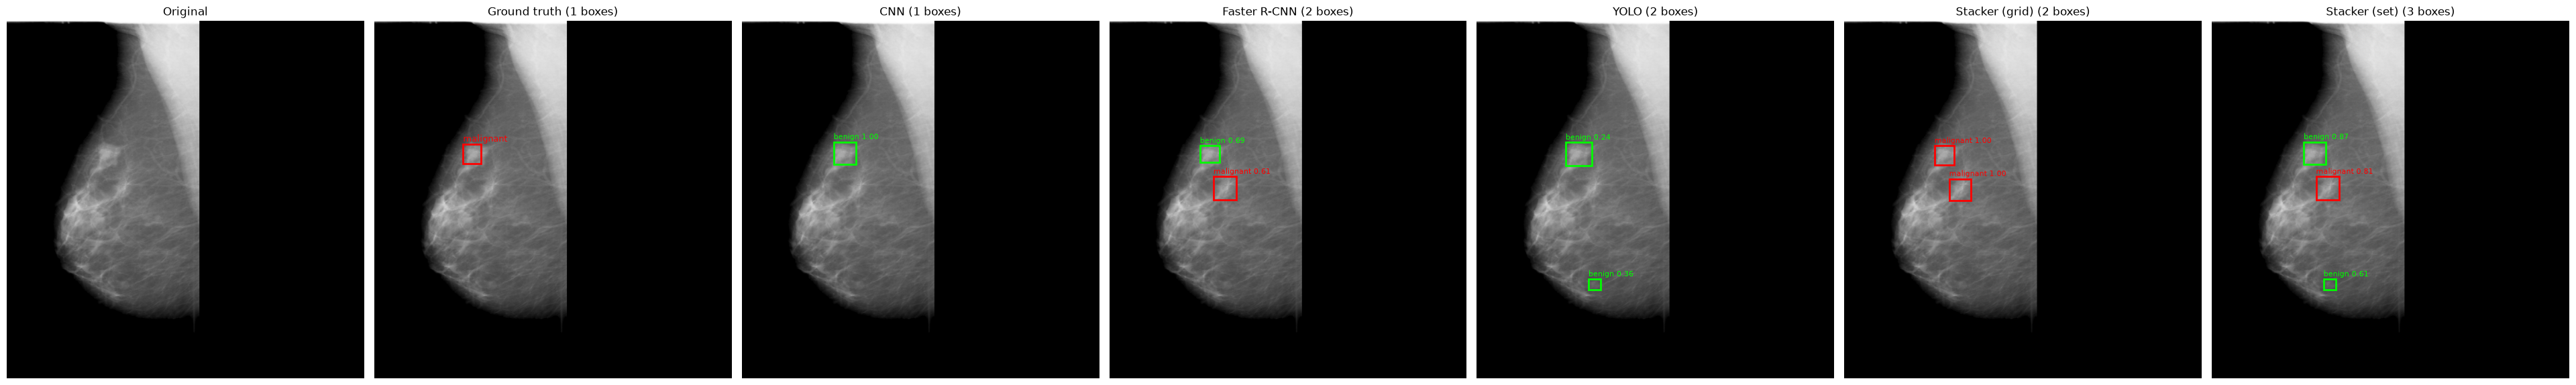

In [11]:
# Block 10
# Qualitative check: three test mammograms with the ground truth and the five ensemble families
SAMPLES = 3

for index in np.linspace(0, len(test_df) - 1, SAMPLES, dtype=int):
    row = test_df.iloc[index]
    entry = ground_truth[ids[index]]
    image = cnn_detector.cnn_prepare_image(row)[0]

    panels = []

    for label, _, _ in by_protocol(ENSEMBLE):
        cut = cut_at(RAW[(label, ENSEMBLE)], OPERATING[(label, ENSEMBLE)])[index]
        panels.append((label, cut["boxes"], cut["scores"], cut["labels"]))

    utility.visualize_comparison(image, entry["gt_boxes"], entry["gt_labels"], panels, config.CLASS_NAMES)

---

## What the numbers say

- **YOLO is the strongest localiser of the ten.** It holds the highest AP50 and the highest
  sensitivity at the 1 false positive per mammogram budget under both protocols, and the
  qualitative panels show why: its boxes land on the lesion rather than around it, where the CNN
  still fires on loose boxes and text. Part of that lead is not architectural, since YOLO starts
  from COCO weights while the CNN trains from scratch.
- **The two stackers re-rank rather than detect.** Their curves sit at or below the union of
  their three inputs, which is the expected ceiling for a model that only orders the candidates
  it is handed. The grid stacker buys AP50 with far more boxes per mammogram, and the set
  stacker gets a comparable curve while holding a usable precision.
- **Benign versus malignant is the weak half for every model.** The per-class sensitivities sit
  well under the localisation numbers, and the confusion matrices show where: most rows are
  background, and the boxes that do land split near the class prior. Neither stacker repairs
  this, because the class evidence they receive is the detectors' own class head.
- **The ensemble protocol wins the detector half.** Five-fold pooling beats the single
  full-trainval retrain on AP50, so the extra training data does not repay the loss of fold
  averaging. The same gap does not appear for the stackers, which are already trained on the
  pooled out-of-fold feed.

Two things to keep in view. The FROC threshold only means anything next to the budget it was
read at, so changing `FROC_FP_BUDGET` moves every threshold-dependent column and leaves AP50 and
the curves alone. And the two protocols are not two independent estimates of one model: the
ensemble averages five models that each saw 80% of trainval, while the full retrain is one model
that saw all of it, with the test split as its only held-out score.